# S³ semantic-axis smoke test

This exploratory test fits Turftopic S³ to the existing semantic passages using the saved BGE-M3 vectors. Passage embeddings are loaded from disk and passed through `embeddings=`; they are not recomputed. The matching local BGE model is used only for vocabulary-term embeddings.

This fit uses 10 components and seed 43. Scores are signed ICA coordinates, not calibrated probabilities or BERTopic topics. Review the displayed positive/negative evidence before interpreting an axis. Original BERTopic assignments are not changed.

Run from the repository root with `uv run --group topic-analysis jupyter lab`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer
from turftopic import SemanticSignalSeparation

project_root = Path.cwd().resolve()
if not (project_root / 'data/topic-analysis').exists():
    project_root = project_root.parent
if not (project_root / 'data/topic-analysis').exists():
    raise FileNotFoundError('Could not locate data/topic-analysis from the notebook working directory')
results = project_root / 'data/topic-analysis/results'
dataset_path = results / 'segment-dataset/all-segments.parquet'
embedding_path = results / 'jev-semantic-all/bubble-maps/segment-embeddings.npy'
embedding_manifest_path = results / 'jev-semantic-all/bubble-maps/embedding-manifest.json'
model_manifest_path = results / 'segment-dataset/manifest.json'
MODEL_ID = 'BAAI/bge-m3'
MODEL_REVISION = '5617a9f61b028005a4858fdac845db406aefb181'
N_COMPONENTS, RANDOM_STATE = 10, 43
print(f'Project: {project_root}')
print(f'Saved vectors: {embedding_path}')

Project: C:\Users\risto\projects\arvamusfestivali_salvestused
Saved vectors: C:\Users\risto\projects\arvamusfestivali_salvestused\data\topic-analysis\results\jev-semantic-all\bubble-maps\segment-embeddings.npy


C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\_snmf.py:20: UserWarning: JAX not found, continuing with NumPy implementation.
  warnings.warn("JAX not found, continuing with NumPy implementation.")


In [2]:
wanted = ['segment_key', 'segmentation', 'passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength']
available = set(pd.read_parquet(dataset_path).columns)
all_passages = pd.read_parquet(dataset_path, columns=[c for c in wanted if c in available])
passages = all_passages.loc[all_passages.segmentation == 'semantic'].reset_index(drop=True)
embedding_manifest = json.loads(embedding_manifest_path.read_text(encoding='utf-8'))
model_info = json.loads(model_manifest_path.read_text(encoding='utf-8'))['models']['semantic']
embeddings = np.load(embedding_path, allow_pickle=False)
assert model_info['embedding_model_id'] == MODEL_ID
assert model_info['embedding_revision'] == MODEL_REVISION
assert int(model_info['embedding_dimension']) == 1024
assert passages.segment_key.tolist() == embedding_manifest['segment_keys'], 'Passage/vector order mismatch'
assert embeddings.shape == (len(passages), 1024), embeddings.shape
assert embeddings.dtype == np.float32 and np.isfinite(embeddings).all()
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1.0, atol=1e-4), 'Vectors are not L2-normalized'
print(f'Validated {len(passages):,} passages × {embeddings.shape[1]} dimensions; float32, finite, L2-normalized.')
print(f"Model: {model_info['embedding_model_id']} @ {model_info['embedding_revision']}")
print(f"Original BERTopic outliers (topic -1): {(passages.topic_id == -1).sum():,}")

Validated 4,132 passages × 1024 dimensions; float32, finite, L2-normalized.
Model: BAAI/bge-m3 @ 5617a9f61b028005a4858fdac845db406aefb181
Original BERTopic outliers (topic -1): 827


## Fit on the precomputed vectors

The encoder is loaded from local cache only. If that exact revision is not cached, the cell fails instead of downloading or substituting another model. Turftopic receives the corpus matrix directly via `embeddings=embeddings`.

In [3]:
encoder = SentenceTransformer(MODEL_ID, revision=MODEL_REVISION, local_files_only=True)
s3 = SemanticSignalSeparation(n_components=N_COMPONENTS, encoder=encoder, vectorizer=CountVectorizer(max_features=500), random_state=RANDOM_STATE)
scores = s3.fit_transform(passages.text.tolist(), embeddings=embeddings)
assert scores.shape == (len(passages), N_COMPONENTS), scores.shape
assert np.isfinite(scores).all(), 'S³ scores contain non-finite values'
score_columns = [f's3_component_{i}' for i in range(N_COMPONENTS)]
scored_passages = passages.copy()
for i, column in enumerate(score_columns):
    scored_passages[column] = scores[:, i]
print(f'S³ fit passed: {len(passages):,} passages, {N_COMPONENTS} components, seed {RANDOM_STATE}.')
print('Passage vectors came from disk; no passage re-embedding was run.')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Output()

C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\sklearn\decompositio
n\_fastica.py:132: ConvergenceWarning: FastICA did not converge. Consider increasing tolerance or the maximum 
number of iterations.
  warnings.warn(

[17:58:34] Decomposition done.                                                                        ]8;id=865845;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=307625;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#156\156]8;;\

[17:58:36] Term extraction done.                                                                      ]8;id=603742;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=101216;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#159\159]8;;\

[17:58:47] Vocabulary encoded.                                                                        ]8;id=326832;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=796518;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#169\169]8;;\

           Model fitting done.                                                                        ]8;id=461360;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py\decomp.py]8;;\:]8;id=196389;file://C:\Users\risto\projects\arvamusfestivali_salvestused\data\state\af-topic-env\Lib\site-packages\turftopic\models\decomp.py#189\189]8;;\

S³ fit passed: 4,132 passages, 10 components, seed 43.
Passage vectors came from disk; no passage re-embedding was run.


## S³ component summary and naming evidence

S³ returns continuous bipolar axes, not discrete topic assignments. The dominant-axis count below is only an exploratory tally: each passage is counted under the component with its largest absolute standardized score. It is not a cluster count or a calibrated classification. For naming, review Turftopic's high/low term lists alongside the positive/negative extreme passages below, then enter a human-reviewed bipolar label; no labels are generated automatically.

In [4]:
score_frame = pd.DataFrame(scores, columns=score_columns)
score_std = score_frame.std(ddof=0).replace(0, 1)
score_z = (score_frame - score_frame.mean()) / score_std
dominant_component_index = np.abs(score_z.to_numpy()).argmax(axis=1)
dominant_counts = pd.Series(dominant_component_index).value_counts().reindex(range(N_COMPONENTS), fill_value=0)
positive_terms = s3.get_top_words(top_k=12, positive=True)
negative_terms = s3.get_top_words(top_k=12, positive=False)

component_stats = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'passage_count': len(score_frame),
    'score_nan_count': score_frame.isna().sum().to_numpy(),
    'positive_score_count': score_frame.gt(0).sum().to_numpy(),
    'negative_score_count': score_frame.lt(0).sum().to_numpy(),
    'mean_score': score_frame.mean().to_numpy(),
    'score_std': score_frame.std(ddof=0).to_numpy(),
    'min_score': score_frame.min().to_numpy(),
    'max_score': score_frame.max().to_numpy(),
    'dominant_axis_passages_exploratory': dominant_counts.to_numpy(),
})
print(f'S³ passages scored: {len(score_frame):,}; missing passage texts: {passages.text.isna().sum():,}; blank passage texts: {(passages.text.notna() & passages.text.astype("string").str.strip().eq("")).sum():,}')
print('Continuous score distribution and exploratory dominant-axis counts (not topic membership)')
display(component_stats)

axis_review = pd.DataFrame({
    'component_id': range(N_COMPONENTS),
    'positive_end_terms': [', '.join(words) for words in positive_terms],
    'negative_end_terms': [', '.join(words) for words in negative_terms],
    'reviewed_bipolar_label': ['' for _ in range(N_COMPONENTS)],
    'review_notes': ['' for _ in range(N_COMPONENTS)],
})
print('Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.')
display(axis_review)
assert int(component_stats.passage_count.iloc[0]) == len(passages)
assert int(component_stats.score_nan_count.sum()) == int(score_frame.isna().sum().sum())
assert int(component_stats.dominant_axis_passages_exploratory.sum()) == len(passages)
print(f"S3_COMPONENT_STATS_OK passages={len(passages):,}; components={N_COMPONENTS}; missing_scores={int(score_frame.isna().sum().sum())}")

S³ passages scored: 4,132; missing passage texts: 0; blank passage texts: 0
Continuous score distribution and exploratory dominant-axis counts (not topic membership)


,component_id,passage_count,score_nan_count,positive_score_count,negative_score_count,mean_score,score_std,min_score,max_score,dominant_axis_passages_exploratory
0,0,4132,0,2012,2120,4.080581e-07,1.0,-3.174698,3.239763,391
1,1,4132,0,2542,1590,3.692834e-07,1.0,-3.908588,2.009524,407
2,2,4132,0,2387,1745,-1.915657e-07,1.0,-4.592851,2.662680,352
3,3,4132,0,2120,2012,9.047443e-08,1.0,-3.180788,2.745695,402
4,4,4132,0,2192,1940,-3.508192e-07,1.0,-3.434308,2.870971,433
5,5,4132,0,1882,2250,1.920274e-07,1.0,-2.795831,3.766644,413
6,6,4132,0,2145,1987,-7.385668e-09,1.0,-3.326883,3.030582,404
7,7,4132,0,2026,2106,-7.477988e-08,1.0,-2.978288,3.136637,421
8,8,4132,0,2049,2083,1.033993e-07,1.0,-3.172971,3.203527,438
9,9,4132,0,2074,2058,4.708363e-08,1.0,-2.750337,2.656178,471


Naming evidence: use both ends of each axis and verify them against the extreme passages in the next cell.


,component_id,positive_end_terms,negative_end_terms,reviewed_bipolar_label,review_notes
0,0,"mingisugune, mingisuguse, mõned, erinevaid, üt...","ai, it, tööle, töö, tööd, sisse, arvan, head, ...",,
1,1,"vot, midagi, kooli, kuidagi, mingit, huvitav, ...","hea, ees, hoida, selles, raske, arust, sest, s...",,
2,2,"vähem, põhimõtteliselt, no, lihtne, vähe, need...","kelle, arutelu, kes, räägime, arvan, olin, ole...",,
3,3,"noh, ai, maailma, arutelu, maailmas, aitäh, ni...","koolis, õpetaja, kooli, tööle, raha, lapsed, t...",,
4,4,"rääkida, inimeste, inimesi, minema, rääkima, i...","it, ai, ega, aeg, arust, ise, oled, tee, kasut...",,
5,5,"euroopa, eest, maailma, oska, eesti, noor, rii...","raha, puhul, asja, lahti, asju, leida, teed, p...",,
6,6,"euroopa, tööle, id, inimest, inimeste, töö, ra...","koolis, õpetaja, kooli, teen, elu, teed, eesmä...",,
7,7,"riigi, riik, euroopa, maailmas, teen, iganes, ...","tööle, tööd, töö, teame, minema, korraks, jook...",,
8,8,"õpetaja, mõtlema, mõelda, ütleb, mõju, inimese...","väike, kuhu, kust, kodus, koht, palun, peale, ...",,
9,9,"riik, riigi, raha, parem, arutelu, jääb, prots...","koolis, jooksul, kodus, ennast, me, sisse, äkk...",,


S3_COMPONENT_STATS_OK passages=4,132; components=10; missing_scores=0


## 2-D view of the S³ axes

Each panel shows the same passage map: a PCA projection of the already-saved embeddings. Color shows the signed standardized S³ score for that panel's axis; outlined points are original BERTopic outliers (`topic_id == -1`). The map is only a 2-D projection and does not define clusters or topics.

The table below gives one strongest positive and negative evidence passage per axis, alongside top terms. These are evidence for human review, not automatic topic names.

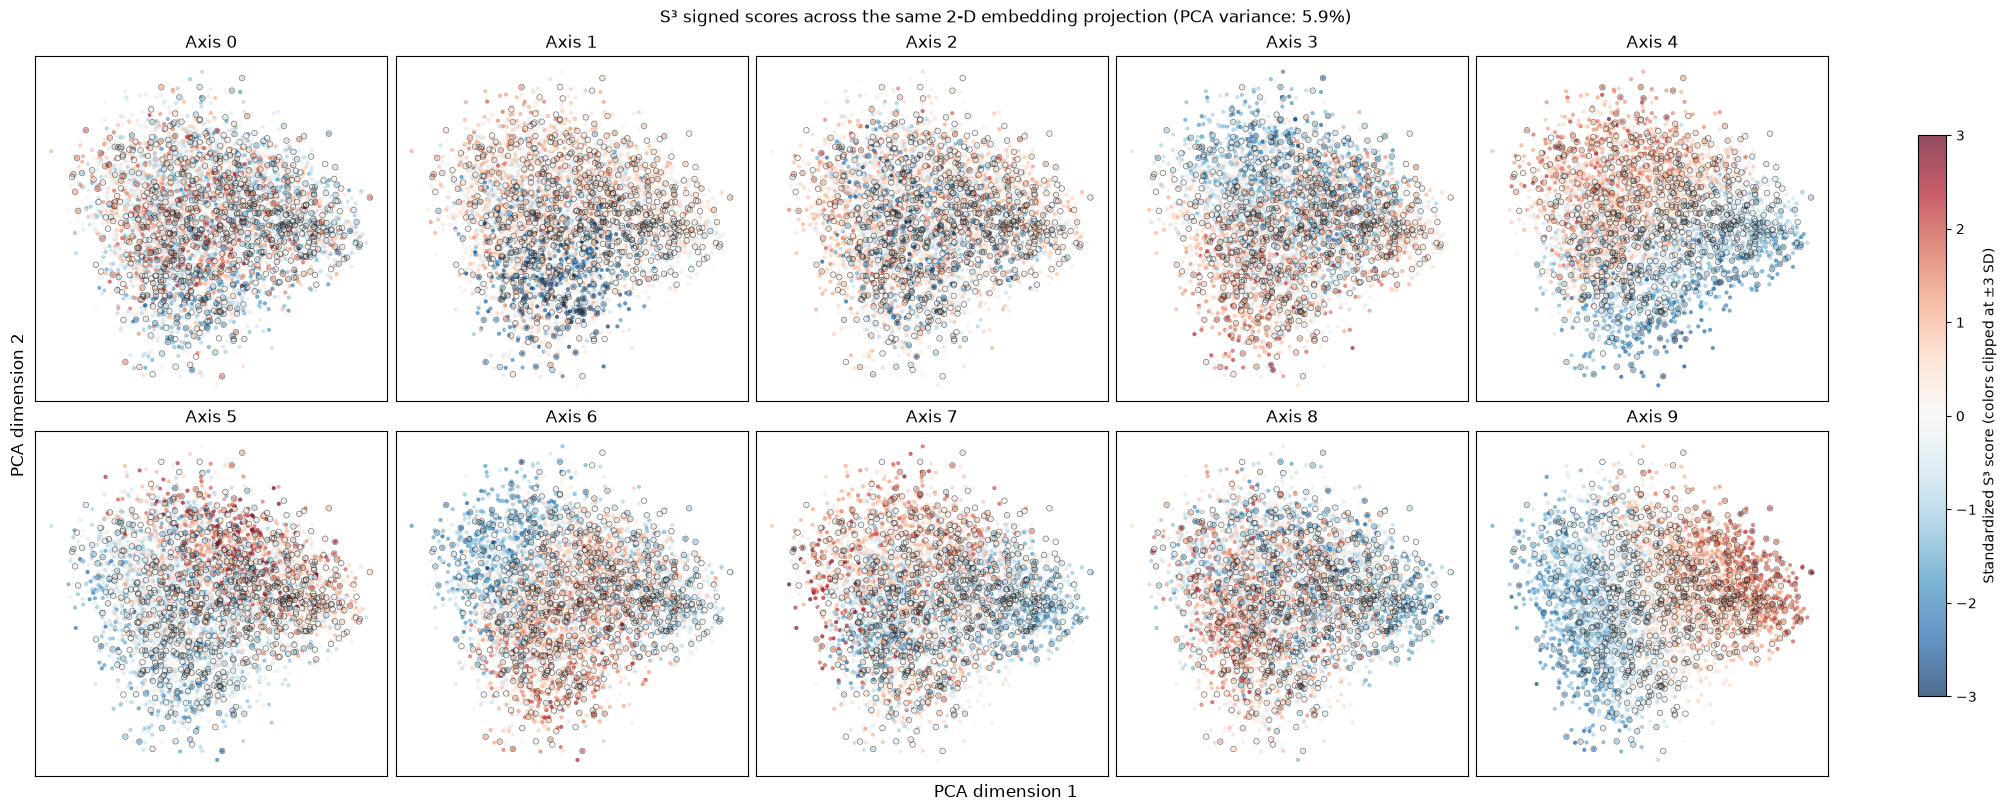

2-D projection uses the saved 1024-D vectors for 4,132 passages; BERTopic outliers outlined: 827.
Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.


,axis,positive terms,positive passage,negative terms,negative passage
0,0,"mingisugune, mingisuguse, mõned, erinevaid, üt...",2293106222 | Süstime rahva saledaks_ | 146.36–...,"ai, it, tööle, töö, tööd, sisse, arvan, head",2247188684 | Kas kiirustades elad kauem? | 450...
1,1,"vot, midagi, kooli, kuidagi, mingit, huvitav, ...",2395857126 | Kuuluvustunne või äärmuslus_ Kuid...,"hea, ees, hoida, selles, raske, arust, sest, s...",2397177255 | Vabakutseliste loovisikute toimet...
2,2,"vähem, põhimõtteliselt, no, lihtne, vähe, need...","2395991463 | Mees, kus su lapsed on_ | 4516.52...","kelle, arutelu, kes, räägime, arvan, olin, ole...",2254333412 | Millist väliruumi ootame oma linn...
3,3,"noh, ai, maailma, arutelu, maailmas, aitäh, ni...",2302899434 | Infraheli ja tuulepargid – müüt v...,"koolis, õpetaja, kooli, tööle, raha, lapsed, t...",2400164913 | Alushariduse agenda 2027–2031_ mi...
4,4,"rääkida, inimeste, inimesi, minema, rääkima, i...",2271676349 | Millised on minu kui kodaniku võ...,"it, ai, ega, aeg, arust, ise, oled, tee","2400184980 | Eesti, Singapur, Dubai, Delaware...."
5,5,"euroopa, eest, maailma, oska, eesti, noor, rii...","2395857123 | Uus elu, uued rollid_ pagulaste i...","raha, puhul, asja, lahti, asju, leida, teed, p...","2300040479 | Mida teha, kui hea nimi satub lai..."
6,6,"euroopa, tööle, id, inimest, inimeste, töö, ra...","2395857132 | Kes vastutab, kui välistöötajad e...","koolis, õpetaja, kooli, teen, elu, teed, eesmä...",2400164913 | Alushariduse agenda 2027–2031_ mi...
7,7,"riigi, riik, euroopa, maailmas, teen, iganes, ...",2289585017 | Vanematega kohtupinki – digilaste...,"tööle, tööd, töö, teame, minema, korraks, jook...",2247188684 | Kas kiirustades elad kauem? | 435...
8,8,"õpetaja, mõtlema, mõelda, ütleb, mõju, inimese...",2395991448 | Töö ei küsi vanust_ | 4273.96–436...,"väike, kuhu, kust, kodus, koht, palun, peale, ...",2397264576 | Kas linnud ja loomad keedavad mei...
9,9,"riik, riigi, raha, parem, arutelu, jääb, prots...","2254333406 | Kuhu pöörad, rohepööre_ | 3750.72...","koolis, jooksul, kodus, ennast, me, sisse, äkk...",2289585029 | Alati ühenduses. Suurem produktii...


In [5]:
projection = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit_transform(embeddings)
assert projection.shape == (len(passages), 2) and np.isfinite(projection).all()
projection_variance = PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE).fit(embeddings).explained_variance_ratio_.sum()
outlier_mask = passages.topic_id.eq(-1).to_numpy()
ncols = min(5, N_COMPONENTS)
nrows = (N_COMPONENTS + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), sharex=True, sharey=True, constrained_layout=True)
axes = np.asarray(axes).reshape(-1)
for component_id, ax in enumerate(axes):
    if component_id >= N_COMPONENTS:
        ax.set_visible(False)
        continue
    values = score_z.iloc[:, component_id].to_numpy()
    ax.scatter(projection[:, 0], projection[:, 1], c=values, cmap='RdBu_r', vmin=-3, vmax=3, s=9, alpha=0.7, linewidths=0, rasterized=True)
    ax.scatter(projection[outlier_mask, 0], projection[outlier_mask, 1], facecolors='none', edgecolors='#222222', s=16, linewidths=0.45, alpha=0.7, rasterized=True)
    ax.set_title(f'Axis {component_id}')
    ax.set_xticks([]); ax.set_yticks([])
fig.supxlabel('PCA dimension 1'); fig.supylabel('PCA dimension 2')
fig.suptitle(f'S³ signed scores across the same 2-D embedding projection (PCA variance: {projection_variance:.1%})')
fig.colorbar(axes.flat[0].collections[0], ax=axes.ravel().tolist(), label='Standardized S³ score (colors clipped at ±3 SD)', shrink=0.78)
plt.show()

assert len(score_z.columns) == N_COMPONENTS
assert len(projection) == len(passages) == len(scored_passages)
assert int(outlier_mask.sum()) == int((passages.topic_id == -1).sum())
print(f'2-D projection uses the saved {embeddings.shape[1]}-D vectors for {len(passages):,} passages; BERTopic outliers outlined: {outlier_mask.sum():,}.')

table_rows = []
for component_id, score_column in enumerate(score_columns):
    positive = scored_passages[score_column].idxmax()
    negative = scored_passages[score_column].idxmin()
    pos = scored_passages.loc[positive]
    neg = scored_passages.loc[negative]
    table_rows.append({
        'axis': component_id,
        'positive terms': ', '.join(positive_terms[component_id][:8]),
        'positive passage': f"{pos.get('episode_id', '')} | {pos.get('title', '')} | {pos.get('start_seconds', '')}–{pos.get('end_seconds', '')}s | BERTopic {pos.get('topic_id', '')} | score {pos[score_column]:.3f} | {pos.get('text', '')}",
        'negative terms': ', '.join(negative_terms[component_id][:8]),
        'negative passage': f"{neg.get('episode_id', '')} | {neg.get('title', '')} | {neg.get('start_seconds', '')}–{neg.get('end_seconds', '')}s | BERTopic {neg.get('topic_id', '')} | score {neg[score_column]:.3f} | {neg.get('text', '')}",
    })
axis_evidence_table = pd.DataFrame(table_rows)
assert len(axis_evidence_table) == N_COMPONENTS
print('Strongest passage at each end of each component; use both poles and review the linked transcript/audio before naming an axis.')
display(axis_evidence_table)

In [6]:
evidence_columns = [c for c in ['passage_id', 'episode_id', 'title', 'start_seconds', 'end_seconds', 'text', 'audio_url', 'topic_id', 'membership_strength'] if c in scored_passages.columns]
for i, score_column in enumerate(score_columns):
    print(f'Component {i}: highest-scoring passages')
    display(scored_passages.nlargest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
    print(f'Component {i}: lowest-scoring passages')
    display(scored_passages.nsmallest(3, score_column)[evidence_columns + [score_column]].reset_index(drop=True))
outliers = scored_passages.loc[scored_passages.topic_id == -1].copy()
outlier_view = outliers[evidence_columns + score_columns].sort_values(score_columns[0], key=lambda x: x.abs(), ascending=False)
print(f'Outliers shown for additional evidence review: {len(outliers):,} total; first 12 by absolute component-0 score.')
display(outlier_view.head(12).reset_index(drop=True))

Component 0: highest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2293106222:000000146360-000000275800,2293106222,Süstime rahva saledaks_,146.36,275.80,"stiile ehk harjumused, mängib toidu kvaliteet ...",47,1.0,3.239763
1,2289585020:000000820440-000000921520,2289585020,Zoomer vs Boomer. Arija ja Marii Laser Techist...,820.44,921.52,hti väga ebameeldiva maitsega. Kas keegi teab ...,207,1.0,3.057505
2,2397264576:000003085440-000003192480,2397264576,Kas linnud ja loomad keedavad meile uut superh...,3085.44,3192.48,"Et nähti, et taus on majanduslikult oluliselt,...",131,1.0,3.047034


Component 0: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0
0,2247188684:000004506880-000005090760,2247188684,Kas kiirustades elad kauem?,4506.88,5090.76,Ma väga tänan. Tuleks veel ja edu siis metsate...,1,0.805689,-3.174698
1,2302899440:000000011800-000000463200,2302899440,Rohetehnoloogiad – puhta tööstuse ja julgeolek...,11.80,463.20,"Aga kena, kell on saanud kaksteist ja natukene...",5,0.490508,-2.699269
2,2395991469:000003685640-000004236640,2395991469,Kes võidab AI-ajastul_,3685.64,4236.64,"oft, Microsoft sisse murtakse, et. Aga võib-ol...",186,1.000000,-2.484688


Component 1: highest-scoring passages


...

,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_9
0,2254333406:000003750720-000003848560,2254333406,"Kuhu pöörad, rohepööre_",3750.72,3848.56,Meie ilmselgelt ka meie see majandusseisukord ...,-1,NaN,2.656178
1,2396670924:000002945840-000003048960,2396670924,Loodusrahvas või ressursirahvas_ miks keskkond...,2945.84,3048.96,"kumisest, eks ole, siis on, me peame tagama au...",-1,NaN,2.567639
2,2323554791:000000785760-000001267000,2323554791,Parlamendierakondade esimeeste debatt,785.76,1267.00,Enesestmõistetavalt Isamaa toetab maksude lang...,174,1.0,2.524971


Component 9: lowest-scoring passages


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_9
0,2289585029:000004546720-000004832560,2289585029,Alati ühenduses. Suurem produktiivsus või läbi...,4546.72,4832.56,Õpimärke lugema. Et siit sinu kunagi me alusta...,11,0.403810,-2.750337
1,2289585020:000004893640-000005086200,2289585020,Zoomer vs Boomer. Arija ja Marii Laser Techist...,4893.64,5086.20,"noh, mina olen püüdnud neid vestlusi pidada, e...",11,0.641323,-2.651444
2,2400184983:000000922680-000001244280,2400184983,"Post-it, pastakas ja AI-agent - Eesti.ai prakt...",922.68,1244.28,Nemad töötavad siis nagu see instruktsioonide ...,9,0.813601,-2.629127


Outliers shown for additional evidence review: 827 total; first 12 by absolute component-0 score.


,passage_id,episode_id,title,start_seconds,end_seconds,text,topic_id,membership_strength,s3_component_0,s3_component_1,s3_component_2,s3_component_3,s3_component_4,s3_component_5,s3_component_6,s3_component_7,s3_component_8,s3_component_9
0,2300040506:000000178360-000000294800,2300040506,"Pärisvabakond teeb asju riigi rahata, eks_",178.36,294.80,Paikuse minut. Mõni on juba varbad kasutusele ...,-1,NaN,2.835893,0.591213,-0.893246,-0.169333,-0.262339,-0.789484,1.272984,-1.239478,-0.044545,-0.801184
1,2396692752:000004845720-000004946560,2396692752,Tuleviku Eesti edulugu_ majanduskasv või tasaa...,4845.72,4946.56,"batiga jõudmas lõppu. Mu hea kolleeg Bianka, k...",-1,NaN,2.716463,0.779806,-1.960273,-0.200780,-0.413954,-0.341040,0.503270,-0.008052,1.614632,0.028069
2,2395857120:000002821160-000002919360,2395857120,Muutuv rändemaastik_ milleks peab Eesti Euroop...,2821.16,2919.36,"de tuhandete tulnute, siis nemad ju ei rännanu...",-1,NaN,2.669548,0.352391,0.724011,-0.523895,0.618898,2.726563,0.317097,0.237117,-0.494403,-0.957270
3,2277338243:000002638320-000002795720,2277338243,Maailmahariduslik mälumäng ja mõtteharjutused ...,2638.32,2795.72,"Väga hea, lähme edasi siis järgmise küsimusega...",-1,NaN,2.561684,0.237492,0.549088,1.005214,-0.869139,0.913406,-0.752367,-0.890501,0.161028,0.643067
4,2397264576:000001808640-000002033320,2397264576,Kas linnud ja loomad keedavad meile uut superh...,1808.64,2033.32,Kas teie olete nõus sööma haige loomaliha? Lõp...,-1,NaN,2.438823,-1.386581,1.046946,0.963082,0.870610,-0.233064,-0.185573,-0.604739,-0.760509,0.127476
5,2395857123:000002362440-000002461160,2395857123,"Uus elu, uued rollid_ pagulaste identiteet ja ...",2362.44,2461.16,Eelmisele ja me anname võimaluse kohanemine on...,-1,NaN,2.419359,0.252546,-0.227115,-0.507565,0.168275,1.569774,0.913794,-0.369315,0.011331,-1.079833
6,2396670930:000002257120-000002354240,2396670930,ÜRO kõnnib Rahvasteliidu teed,2257.12,2354.24,"lid, mida ma ei tea, mille puhul öeldakse, et,...",-1,NaN,2.411973,0.198188,0.472557,-1.083431,-1.535871,0.928561,1.773846,0.426537,0.521757,1.068024
7,2254333406:000001098120-000001191760,2254333406,"Kuhu pöörad, rohepööre_",1098.12,1191.76,"Isegi sõltumata sellest, kas tuleb üks või tei...",-1,NaN,2.408860,-0.516735,0.743705,0.888086,-1.460196,1.346816,-0.874017,-0.777396,1.935456,1.427771
8,2395857138:000001345400-000001445880,2395857138,"Do They Belong Here, Or Do They Just Live Here_",1345.40,1445.88,"n't understand anything in June, for example, ...",-1,NaN,2.407944,0.645610,0.400986,-0.003397,-0.907127,0.709877,0.529006,-0.315129,-1.097904,-1.238555
9,2396692752:000004299880-000004401120,2396692752,Tuleviku Eesti edulugu_ majanduskasv või tasaa...,4299.88,4401.12,"Et noh, siin oli ka Ansip ütleb, tahame saama ...",-1,NaN,2.391683,0.754777,0.497266,-1.244390,0.231861,0.657372,0.090998,1.095953,1.556563,1.268799
